In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 
import warnings 
warnings.filterwarnings('ignore')

In [18]:
df = pd.read_csv(r"fitness-recommendation-dataset.csv")

In [19]:
df.head()

,ID,Sex,Age,Height,Weight,Hypertension,Diabetes,BMI,Level,Fitness Goal,Fitness Type,Exercises,Equipment,Diet,Recommendation
0,1,Male,18,1.68,47.5,No,No,16.83,Underweight,Weight Gain,Muscular Fitness,"Squats, deadlifts, bench presses, and overhead...",Dumbbells and barbells,"Vegetables: (Carrots, Sweet Potato, and Lettuc...",Follow a regular exercise schedule. Adhere to ...
1,2,Male,18,1.68,47.5,Yes,No,16.83,Underweight,Weight Gain,Muscular Fitness,"Squats, deadlifts, bench presses, and overhead...","Light athletic shoes, resistance bands, and li...","Vegetables: (Tomatoes, Garlic, leafy greens, b...",Follow a regular exercise schedule. Adhere to ...
2,3,Male,18,1.68,47.5,No,Yes,16.83,Underweight,Weight Gain,Muscular Fitness,"Squats, yoga, deadlifts, bench presses, and ov...","Dumbbells, barbells and Blood glucose monitor","Vegetables: (Garlic, Roma Tomatoes, Capers and...",Follow a regular exercise schedule. Adhere to ...
3,4,Male,18,1.68,47.5,Yes,Yes,16.83,Underweight,Weight Gain,Muscular Fitness,"Squats, yoga, deadlifts, bench presses, and ov...","Light athletic shoes, resistance bands, light ...","Vegetables: (Garlic, Roma Tomatoes, Capers, Gr...",Follow a regular exercise schedule. Adhere to ...
4,5,Male,18,1.68,47.5,No,No,16.83,Underweight,Weight Gain,Muscular Fitness,"Squats, deadlifts, bench presses, and overhead...",Dumbbells and barbells,"Vegetables: (Carrots, Sweet Potato, Lettuce); ...",Follow a regular exercise schedule. Adhere to ...


In [20]:
df.shape

(14589, 15)

In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14589 entries, 0 to 14588
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ID              14589 non-null  int64  
 1   Sex             14589 non-null  str    
 2   Age             14589 non-null  int64  
 3   Height          14589 non-null  float64
 4   Weight          14589 non-null  float64
 5   Hypertension    14589 non-null  str    
 6   Diabetes        14589 non-null  str    
 7   BMI             14589 non-null  float64
 8   Level           14589 non-null  str    
 9   Fitness Goal    14589 non-null  str    
 10  Fitness Type    14589 non-null  str    
 11  Exercises       14589 non-null  str    
 12  Equipment       14589 non-null  str    
 13  Diet            14589 non-null  str    
 14  Recommendation  14589 non-null  str    
dtypes: float64(3), int64(2), str(10)
memory usage: 21.5 MB


In [22]:
df.describe()

,ID,Age,Height,Weight,BMI
count,14589.000000,14589.000000,14589.000000,14589.000000,14589.000000
mean,7295.000000,39.554870,1.699851,70.505991,24.417569
std,4211.625874,13.192655,0.098129,20.030635,6.765144
min,1.000000,18.000000,1.300000,32.000000,9.520000
25%,3648.000000,28.000000,1.640000,55.000000,18.940000
50%,7295.000000,39.000000,1.680000,70.000000,25.250000
75%,10942.000000,51.000000,1.770000,86.000000,29.320000
max,14589.000000,63.000000,2.030000,130.000000,70.000000


In [23]:
df.isnull().sum()

ID                0
Sex               0
Age               0
Height            0
Weight            0
Hypertension      0
Diabetes          0
BMI               0
Level             0
Fitness Goal      0
Fitness Type      0
Exercises         0
Equipment         0
Diet              0
Recommendation    0
dtype: int64

In [24]:
df.drop('ID', axis=1).duplicated().sum()

np.int64(2437)

In [25]:
recommendation = df['Recommendation']
df = df.drop(['ID', 'Recommendation'], axis=1)
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)

(12152, 13)


In [26]:
df['Level'] = df['Level'].replace('Obuse', 'Obese')
df['Level'].value_counts()

Level
Overweight     3375
Normal         3040
Underweight    2896
Obese          2841
Name: count, dtype: int64

In [27]:
for col in ['Sex', 'Hypertension', 'Diabetes', 'Level', 'Fitness Goal']:
    print(df[col].value_counts(), '\n')

Sex
Male      7309
Female    4843
Name: count, dtype: int64 

Hypertension
No     6575
Yes    5577
Name: count, dtype: int64 

Diabetes
No     6574
Yes    5578
Name: count, dtype: int64 

Level
Overweight     3375
Normal         3040
Underweight    2896
Obese          2841
Name: count, dtype: int64 

Fitness Goal
Weight Loss    6216
Weight Gain    5936
Name: count, dtype: int64 



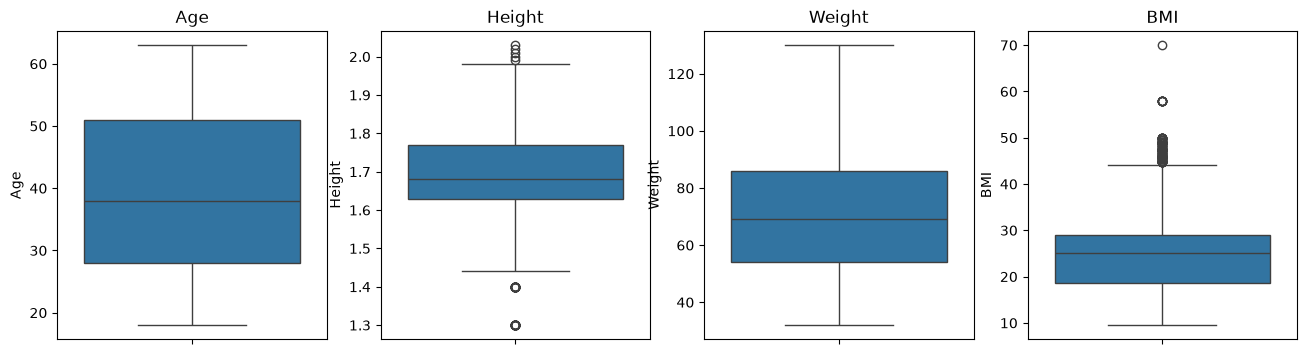

In [28]:
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for i, col in enumerate(['Age', 'Height', 'Weight', 'BMI']):
    sns.boxplot(y=df[col], ax=ax[i])
    ax[i].set_title(col)
plt.show()

In [32]:
df['Level'].unique().tolist()

['Underweight', 'Normal', 'Overweight', 'Obese']

In [35]:
df.columns

Index(['Sex', 'Age', 'Height', 'Weight', 'Hypertension', 'Diabetes', 'BMI',
       'Level', 'Fitness Goal', 'Fitness Type', 'Exercises', 'Equipment',
       'Diet'],
      dtype='str')

In [36]:
##Checking Outliers

In [48]:
num_features = df.select_dtypes(include='number') #int64 or float64
Q1  = num_features.quantile(0.25)
Q3  = num_features.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = (num_features < lower_bound) | (num_features > upper_bound)
print(outliers.sum())
     


Age        0
Height    69
Weight     0
BMI       99
dtype: int64


## Outlier Analysis
- IQR method found 69 outliers in Height and 107 in BMI. Age and Weight had none.
- Outliers appear only in the Underweight and Obese levels, which are open-ended BMI categories. They are valid extreme cases and were retained.

In [37]:
print((df['BMI'] > 40).sum(), (df['BMI'] < 15).sum())

191 711


In [38]:
pd.crosstab(df['Level'], df['Fitness Goal'])

Fitness Goal,Weight Gain,Weight Loss
Level,,
Normal,3040,0
Obese,0,2841
Overweight,0,3375
Underweight,2896,0


In [39]:
df.groupby(['Fitness Goal', 'Hypertension', 'Diabetes'])[['Exercises', 'Equipment', 'Diet']].nunique()

Exercises  Equipment  Diet
Fitness Goal Hypertension Diabetes                            
Weight Gain  No           No                2          8    11
                          Yes               2          8    11
             Yes          No                2          8    11
                          Yes               2          8    11
Weight Loss  No           No                2          8    10
                          Yes               2          7     7
             Yes          No                2          7     8
                          Yes               2          7     6

In [40]:
print((df['Diet'] == 'Diet').sum(), (df['Equipment'] == 'Equipment Required').sum())

27 27


In [41]:
df = df[(df['Diet'] != 'Diet') & (df['Equipment'] != 'Equipment Required')].reset_index(drop=True)
df.shape

(12125, 13)

<Axes: >

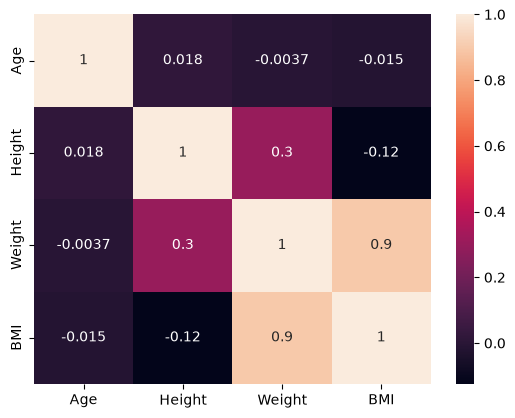

In [43]:
sns.heatmap(df[['Age', 'Height', 'Weight', 'BMI']].corr(), annot=True)


## Correlation Analysis
- Weight and BMI are strongly positively correlated (0.90), since BMI is calculated from Weight.
- Height and Weight have a weak positive correlation (0.30).
- Age shows no meaningful correlation with any numeric feature.

array([[<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Height'}>],
       [<Axes: title={'center': 'Weight'}>,
        <Axes: title={'center': 'BMI'}>]], dtype=object)

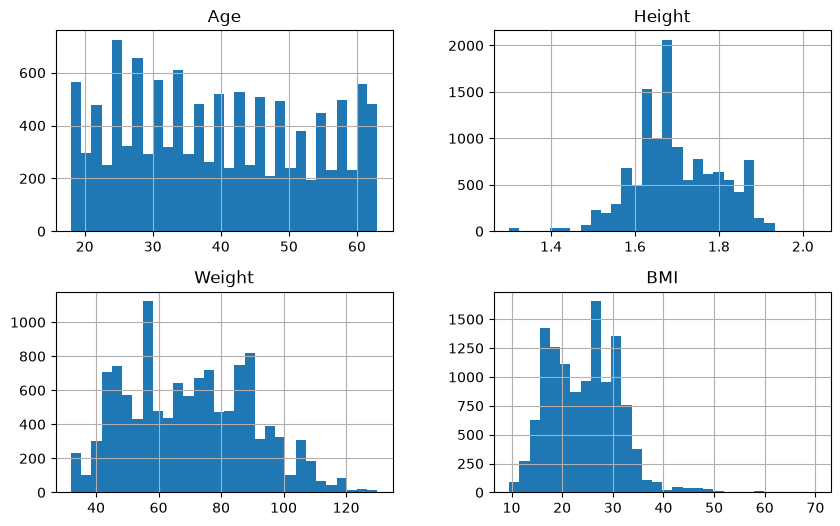

In [44]:
df[['Age', 'Height', 'Weight', 'BMI']].hist(bins=30, figsize=(10, 6))


<Axes: xlabel='BMI', ylabel='Count'>

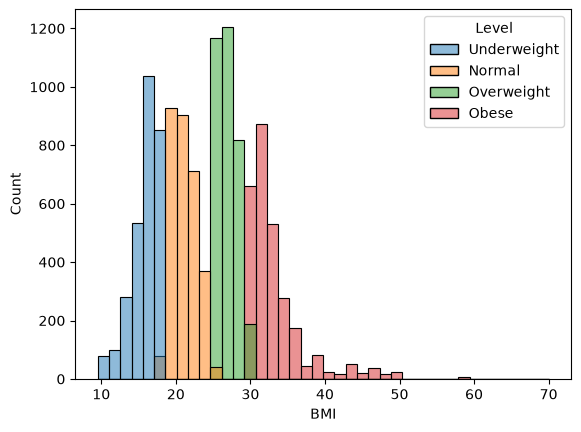

In [45]:
sns.histplot(data=df, x='BMI', hue='Level', bins=40)


<Axes: xlabel='Level', ylabel='BMI'>

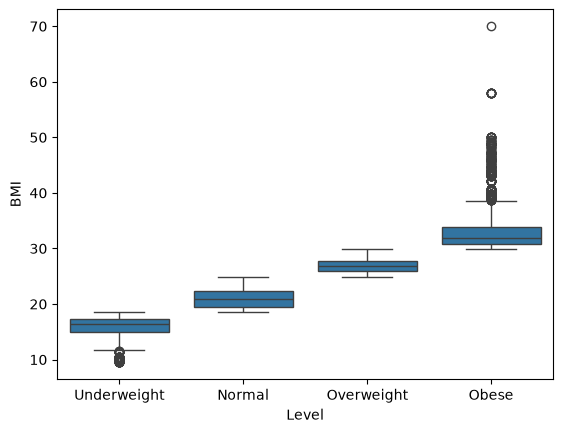

In [46]:
sns.boxplot(x='Level', y='BMI', data=df,order=['Underweight', 'Normal', 'Overweight', 'Obese'])


<Axes: xlabel='Level', ylabel='count'>

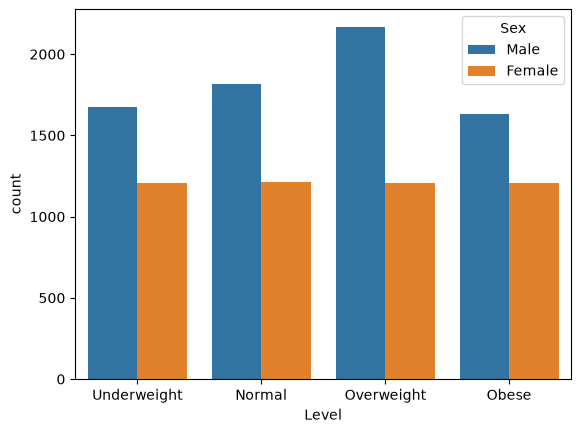

In [47]:
sns.countplot(x='Level', hue='Sex', data=df,
              order=['Underweight', 'Normal', 'Overweight', 'Obese'])


## Sex vs Level
- Males make up about 60% of the data and outnumber females in every Level.
- No strong association between Sex and Level was found.

<Axes: xlabel='Hypertension', ylabel='Age'>

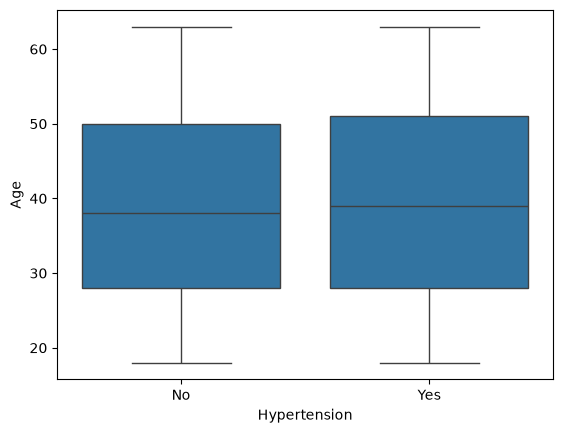

In [49]:
sns.boxplot(x='Hypertension', y='Age', data=df)


## Age vs Hypertension
- Age distribution is almost identical for people with and without Hypertension, and there are no outliers.
- This is unusual compared to real-world data, which suggests the dataset is synthetic. This is noted as a limitation.

<Axes: xlabel='Diabetes', ylabel='Age'>

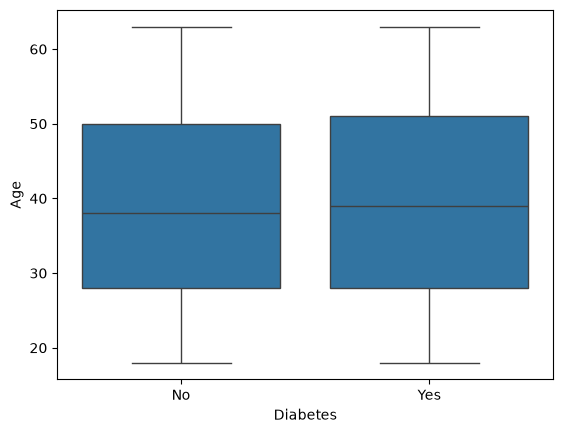

In [50]:
sns.boxplot(x='Diabetes',y='Age',data=df)

## Age vs Diabetes
- Age distribution is nearly identical for people with and without Diabetes, so Age has no visible effect on either health condition in this dataset.

In [51]:
pd.crosstab(df['Hypertension'], df['Diabetes'])

Diabetes,No,Yes
Hypertension,,
No,3777,2784
Yes,2783,2781


## Hypertension vs Diabetes
- No/No is the largest group (3,777). The other three combinations (No/Yes, Yes/No, Yes/Yes) are almost equal (~2,780 each).
- Real-world data would show far fewer people with both conditions, which again suggests the dataset is synthetic.

In [52]:
df['Exercises'].value_counts()

Exercises
Brisk walking, cycling, swimming, running , or dancing.         3437
Squats, deadlifts, bench presses, and overhead presses          3123
Squats, yoga, deadlifts, bench presses, and overhead presses    2786
Walking, Yoga, Swimming.                                        1390
brisk walking, cycling, swimming, or dancing.                   1389
Name: count, dtype: int64

In [55]:
df['Equipment'].value_counts()

Equipment
Ellipticals, Indoor Rowers,Treadmills, Rowing machine                                   2764
Dumbbells and barbells                                                                  1737
Dumbbells, barbells and Blood glucose monitor                                           1399
Light athletic shoes, resistance bands, and light dumbbells.                            1398
Light athletic shoes, resistance bands, light dumbbells and a Blood glucose monitor.    1397
Kettlebell, Dumbbells, Yoga Mat                                                         1385
Kettlebell, Dumbbells, Yoga Mat, Treadmill                                              1385
Ellipticals, Indoor Rowers,Treadmills, and Rowing machine                                660
Name: count, dtype: int64

In [56]:
df['Diet'].value_counts()

Diet
Vegetables: (Garlic, Mushroom, Green Papper, Icebetg Lettuce); Protein Intake: (Baru Nuts, Beech Nuts, Hemp Seeds, Cheese Spandwich); Juice: (Apple Juice, Mango juice,and Beetroot juice)                                                                      4155
Vegetables: (Broccoli, Carrots, Spinach, Lettuce, Onion); Protein Intake: (Cheese, Cattoge cheese, Skim Milk, Law fat Milk, and Baru Nuts); Juice: (Fruit Juice, Aloe vera juice, Cold-pressed juice, and Watermelon juice)                                     2039
Vegetables: (Garlic, Roma Tomatoes, Capers, Green Papper, and Iceberg Lettuce); Protein Intake: (Cheese Sandwich, Baru Nuts, Beech Nuts, Squash Seeds, Mixed Teff, peanut butter, and jelly sandwich); Juice: (Apple juice, beetroot juice, and mango juice)    1397
Vegetables: (Mixed greens, cherry tomatoes, cucumbers, bell peppers, carrots, celery, bell peppers);Protein Intake: (Chicken, fish, tofu, or legumes); Juice : (Green juice,kale, spinach, cucumber, celery, and app

In [57]:
df[['Exercises', 'Equipment', 'Diet']].nunique()

Exercises     5
Equipment     8
Diet         10
dtype: int64

In [58]:
for i in ['Exercises', 'Equipment', 'Diet']:
    print(i, list(df[i].value_counts().values))

Exercises [np.int64(3437), np.int64(3123), np.int64(2786), np.int64(1390), np.int64(1389)]
Equipment [np.int64(2764), np.int64(1737), np.int64(1399), np.int64(1398), np.int64(1397), np.int64(1385), np.int64(1385), np.int64(660)]
Diet [np.int64(4155), np.int64(2039), np.int64(1397), np.int64(939), np.int64(703), np.int64(702), np.int64(696), np.int64(696), np.int64(399), np.int64(399)]


## Target Class Distribution
- Exercises (5 classes) is fairly balanced. Equipment (8 classes) and Diet (10 classes) are moderately imbalanced; the smallest class has 399 records.
- No class was removed. Stratified splitting, class weights and F1-score will be used to handle the imbalance.
- Targets are not fully determined by the inputs (the same Goal, Hypertension and Diabetes combination has several different recommendations), so perfect accuracy is not expected.

In [59]:
df['Sex'] = df['Sex'].map({'Male': 1, 'Female': 0})
df['Hypertension'] = df['Hypertension'].map({'No': 0, 'Yes': 1})
df['Diabetes'] = df['Diabetes'].map({'No': 0, 'Yes': 1})


In [61]:
df.head()

,Sex,Age,Height,Weight,Hypertension,Diabetes,BMI,Level,Fitness Goal,Fitness Type,Exercises,Equipment,Diet
0,1,18,1.68,47.5,0,0,16.83,Underweight,Weight Gain,Muscular Fitness,"Squats, deadlifts, bench presses, and overhead...",Dumbbells and barbells,"Vegetables: (Carrots, Sweet Potato, and Lettuc..."
1,1,18,1.68,47.5,1,0,16.83,Underweight,Weight Gain,Muscular Fitness,"Squats, deadlifts, bench presses, and overhead...","Light athletic shoes, resistance bands, and li...","Vegetables: (Tomatoes, Garlic, leafy greens, b..."
2,1,18,1.68,47.5,0,1,16.83,Underweight,Weight Gain,Muscular Fitness,"Squats, yoga, deadlifts, bench presses, and ov...","Dumbbells, barbells and Blood glucose monitor","Vegetables: (Garlic, Roma Tomatoes, Capers and..."
3,1,18,1.68,47.5,1,1,16.83,Underweight,Weight Gain,Muscular Fitness,"Squats, yoga, deadlifts, bench presses, and ov...","Light athletic shoes, resistance bands, light ...","Vegetables: (Garlic, Roma Tomatoes, Capers, Gr..."
4,1,18,1.68,47.5,0,0,16.83,Underweight,Weight Gain,Muscular Fitness,"Squats, deadlifts, bench presses, and overhead...",Dumbbells and barbells,"Vegetables: (Carrots, Sweet Potato, Lettuce); ..."


In [62]:
df.columns

Index(['Sex', 'Age', 'Height', 'Weight', 'Hypertension', 'Diabetes', 'BMI',
       'Level', 'Fitness Goal', 'Fitness Type', 'Exercises', 'Equipment',
       'Diet'],
      dtype='str')

In [63]:
num_cols = df.select_dtypes(include='number')
num_cols.skew()
# near to 0 -> Centralized (0.01, 0.002)
# negative -> Left Skewed (-1.56)
# poistive (greater than 0) -> Right Skewed (1.256)

Sex            -0.413564
Age             0.160442
Height          0.027017
Weight          0.265089
Hypertension    0.165033
Diabetes        0.164700
BMI             0.467110
dtype: float64

# Exploratory Data Analysis Complete – Starting Model Building

## EDA Summary
- Dataset cleaned to 12,125 rows and 13 columns (removed ID, Recommendation, 2,437 duplicates and 27 corrupted rows). No missing values.
- Age, Height, Weight and BMI are approximately symmetric (skewness within ±0.5). Outliers in Height and BMI are valid extreme cases and were retained.
- Level is derived from BMI, and Fitness Goal follows from Level. Weight and BMI are strongly correlated (0.90).
- Age shows no relationship with Hypertension or Diabetes, which suggests the dataset is synthetic.
- Targets (Exercises: 5, Equipment: 8, Diet: 10 classes) are moderately imbalanced and not fully determined by the inputs.

## Model Building Plan
1. Split the data into train (70%) and test (30%).
2. Build a preprocessing pipeline: StandardScaler for numeric features, ordinal encoding for Level, one-hot encoding for Sex, Hypertension, Diabetes and Fitness Goal.
3. Fit the preprocessor on the training set only, to avoid data leakage.
4. Encode the three targets and train a classification model for each.

In [68]:
from sklearn.model_selection import train_test_split

numeric_cols = ['Age', 'Height', 'Weight', 'BMI']
ordinal_col  = ['Level']
nominal_cols = ['Sex', 'Hypertension', 'Diabetes', 'Fitness Goal']

feature_col = numeric_cols + ordinal_col + nominal_cols
X = df[feature_col]
y = df[['Exercises', 'Equipment', 'Diet']]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

print(X_train.shape, X_test.shape)

(8487, 9) (3638, 9)


In [69]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer

#1. Numeric Features
plain_numeric_pipeline = Pipeline(steps=[
    ('scale',StandardScaler())
])

#2. Ordinal
ordinal_pipeline = Pipeline(steps=[
    ('encode', OrdinalEncoder(categories=[['Underweight', 'Normal', 'Overweight', 'Obese']]))
])

#3. Nominal Features
nominal_pipeline = Pipeline(steps=[
    ('encode', OneHotEncoder(handle_unknown="ignore"))
])


    # (konsi_pipeline, konsa_feature)
preprocessor = ColumnTransformer(transformers=[
    ("Plain_Numeric", plain_numeric_pipeline, numeric_cols),
    ('Ordinal', ordinal_pipeline, ordinal_col),
    ('Normal', nominal_pipeline, nominal_cols)
])

In [70]:
X_train_p = preprocessor.fit_transform(X_train)
X_test_p  = preprocessor.transform(X_test)
print(X_train_p.shape, X_test_p.shape)

(8487, 13) (3638, 13)


## Model Building

# Logistic Regression(Baseline)


In [72]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

for target in ['Exercises', 'Equipment', 'Diet']:
    lr_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
    ])

    lr_pipeline.fit(X_train, y_train[target])
    lr_preds       = lr_pipeline.predict(X_test)
    lr_preds_train = lr_pipeline.predict(X_train)

    print(target)
    print(f"  Training Accuracy: {accuracy_score(y_train[target], lr_preds_train):.3f}")
    print(f"  Testing Accuracy:  {accuracy_score(y_test[target], lr_preds):.3f}")
    print(f"  Testing F1 (macro): {f1_score(y_test[target], lr_preds, average='macro'):.3f}\n")

Exercises
  Training Accuracy: 0.996
  Testing Accuracy:  0.996
  Testing F1 (macro): 0.995

Equipment
  Training Accuracy: 0.890
  Testing Accuracy:  0.886
  Testing F1 (macro): 0.885

Diet
  Training Accuracy: 0.924
  Testing Accuracy:  0.925
  Testing F1 (macro): 0.900



## Random Forest (default settings)
Same preprocessor, different model at the end — that's the entire point of building the pipeline once.

In [75]:
from sklearn.ensemble import RandomForestClassifier

for target in ['Exercises', 'Equipment', 'Diet']:
    rf_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42))
    ])

    rf_pipeline.fit(X_train, y_train[target])
    rf_preds       = rf_pipeline.predict(X_test)
    rf_preds_train = rf_pipeline.predict(X_train)

    print(target)
    print(f"  Training Accuracy: {accuracy_score(y_train[target], rf_preds_train):.3f}")
    print(f"  Testing Accuracy:  {accuracy_score(y_test[target], rf_preds):.3f}")
    print(f"  Testing F1 (macro): {f1_score(y_test[target], rf_preds, average='macro'):.3f}\n")

Exercises
  Training Accuracy: 1.000
  Testing Accuracy:  0.996
  Testing F1 (macro): 0.996

Equipment
  Training Accuracy: 0.993
  Testing Accuracy:  0.917
  Testing F1 (macro): 0.914

Diet
  Training Accuracy: 0.983
  Testing Accuracy:  0.922
  Testing F1 (macro): 0.881



## Hyperparameter Tuning the Random Forest(GridSearchCV)

In [76]:
from sklearn.model_selection import GridSearchCV

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(class_weight='balanced', random_state=42))
])

param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [5, 10, 20, None],
    'classifier__min_samples_leaf': [1, 5, 10]
}

grid = GridSearchCV(rf_pipeline, param_grid, cv=3, scoring='f1_macro', n_jobs=-1)
grid.fit(X_train, y_train['Diet'])

print('Best params:', grid.best_params_)
print('Best CV F1:', round(grid.best_score_, 3))

best_preds = grid.predict(X_test)
print('Testing Accuracy:', round(accuracy_score(y_test['Diet'], best_preds), 3))
print('Testing F1 (macro):', round(f1_score(y_test['Diet'], best_preds, average='macro'), 3))

Best params: {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 100}
Best CV F1: 0.901
Testing Accuracy: 0.928
Testing F1 (macro): 0.902


In [77]:
grid_eq = GridSearchCV(rf_pipeline, param_grid, cv=3, scoring='f1_macro', n_jobs=-1)
grid_eq.fit(X_train, y_train['Equipment'])

print('Best params:', grid_eq.best_params_)
print('Best CV F1:', round(grid_eq.best_score_, 3))

best_preds_eq = grid_eq.predict(X_test)
print('Testing Accuracy:', round(accuracy_score(y_test['Equipment'], best_preds_eq), 3))
print('Testing F1 (macro):', round(f1_score(y_test['Equipment'], best_preds_eq, average='macro'), 3))

Best params: {'classifier__max_depth': 20, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 100}
Best CV F1: 0.91
Testing Accuracy: 0.919
Testing F1 (macro): 0.916


## Saving the Models
- All three final models are saved in one file with joblib, so the Streamlit app can load them without retraining.

In [78]:
final_ex = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])
final_ex.fit(X_train, y_train['Exercises'])

final_eq   = grid_eq.best_estimator_
final_diet = grid.best_estimator_

print('Final models ready')

Final models ready


In [79]:
import joblib

joblib.dump({'Exercises': final_ex, 'Equipment': final_eq, 'Diet': final_diet}, 'fitness_models.pkl')
print('Saved')

Saved
